In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/adult_dataset.csv')

In [ ]:
df.shape

(48842, 15)

In [ ]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [ ]:

df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [ ]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


# Missing value handling
numerical with mean/median and categorical with mode

In [ ]:
df.isna().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [ ]:
# age and Hours per week are numerical columns
# workclass,occupation, native country are categorical

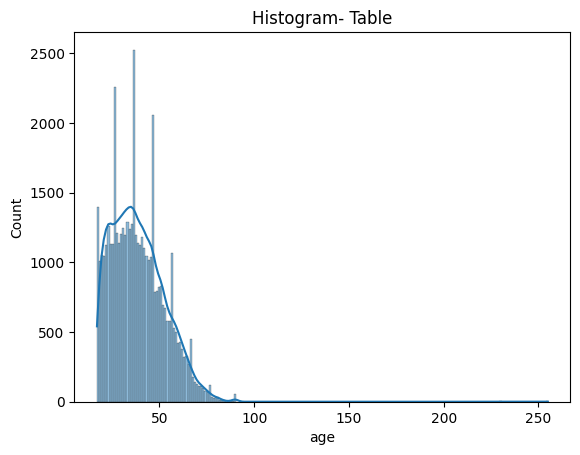

In [ ]:
sns.histplot(df['age'],kde =True)
plt.title('Histogram- Table')
plt.show()

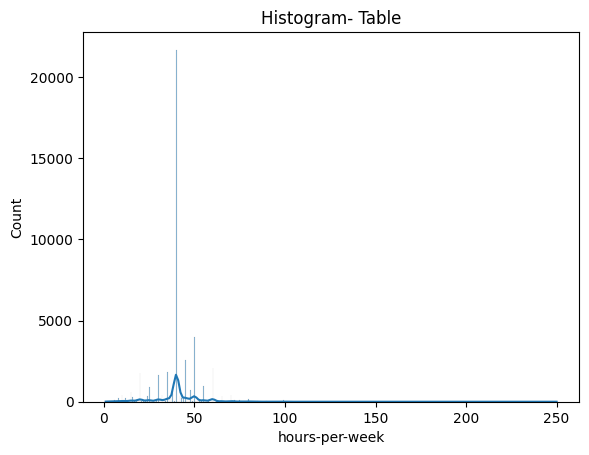

In [ ]:
sns.histplot(df['hours-per-week'],kde =True)
plt.title('Histogram- Table')
plt.show()

In [ ]:
from sklearn.impute import SimpleImputer
imputer1 =SimpleImputer(strategy = 'median')
df['age'] =imputer1.fit_transform(df[['age']])

imputer2 =SimpleImputer(strategy = 'median')
df['hours-per-week'] =imputer2.fit_transform(df[['hours-per-week']])

In [ ]:
df['workclass'].unique()

array(['State-gov', 'Self-emp-not-inc', 'Private', 'Federal-gov', nan,
       'Local-gov', '?', 'Self-emp-inc', 'Without-pay', 'Never-worked'],
      dtype=object)

In [ ]:
df['occupation'].unique()

array(['Adm-clerical', 'Exec-managerial', 'Handlers-cleaners',
       'Prof-specialty', 'Other-service', 'Sales', 'Craft-repair',
       'Transport-moving', 'Farming-fishing', 'Machine-op-inspct',
       'Tech-support', nan, 'Protective-serv', '?', 'Armed-Forces',
       'Priv-house-serv'], dtype=object)

In [ ]:
df['native-country'].unique()

array([nan, 'United-States', 'Cuba', 'Jamaica', 'India', '?', 'Mexico',
       'South', 'Puerto-Rico', 'Honduras', 'England', 'Germany', 'Iran',
       'Philippines', 'Italy', 'Columbia', 'Cambodia', 'Thailand',
       'Canada', 'Ecuador', 'Laos', 'Taiwan', 'Haiti', 'Portugal',
       'Dominican-Republic', 'El-Salvador', 'Poland', 'France',
       'Guatemala', 'China', 'Japan', 'Yugoslavia', 'Peru',
       'Outlying-US(Guam-USVI-etc)', 'Scotland', 'Trinadad&Tobago',
       'Greece', 'Nicaragua', 'Vietnam', 'Hong', 'Ireland', 'Hungary',
       'Holand-Netherlands'], dtype=object)

replacing ? with none and replacing missing values with mode

In [ ]:
df['workclass'] = df['workclass'].replace('?', np.nan)


In [ ]:
imputer_c =SimpleImputer(strategy = 'most_frequent')
df[['workclass']] =imputer_c.fit_transform(df[['workclass']])

In [ ]:
df['occupation'] = df['occupation'].replace('?', np.nan)
imputer_c =SimpleImputer(strategy = 'most_frequent')
df[['occupation']] =imputer_c.fit_transform(df[['occupation']])

In [ ]:
df['native-country'] = df['native-country'].replace('?', np.nan)
imputer_c =SimpleImputer(strategy = 'most_frequent')
df[['native-country']] =imputer_c.fit_transform(df[['native-country']])

In [ ]:
df.isna().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [ ]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

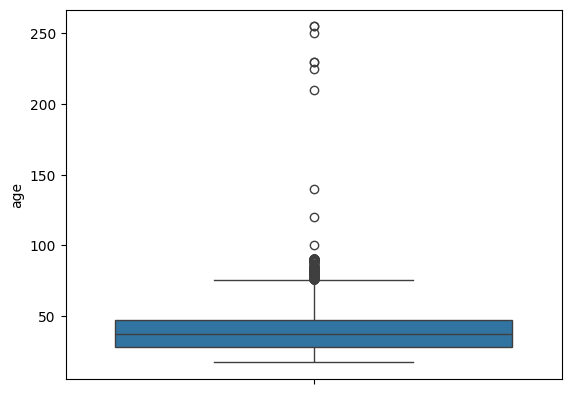

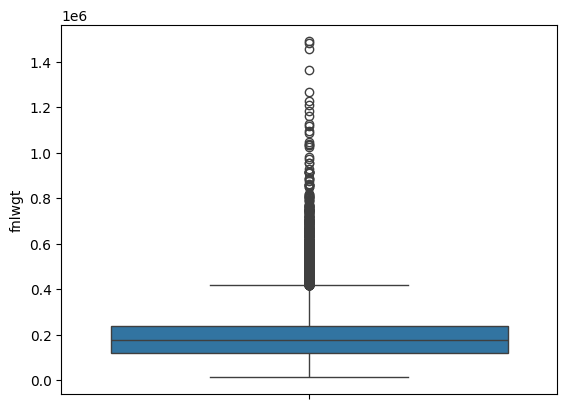

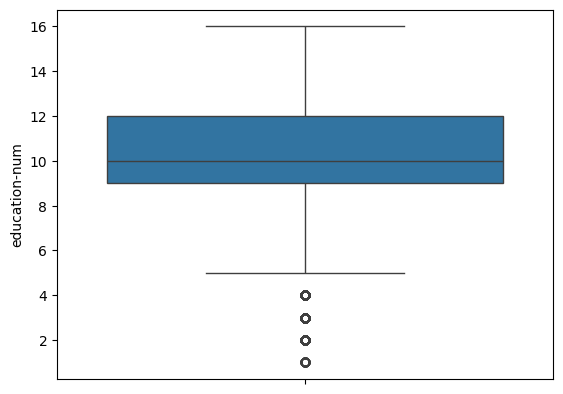

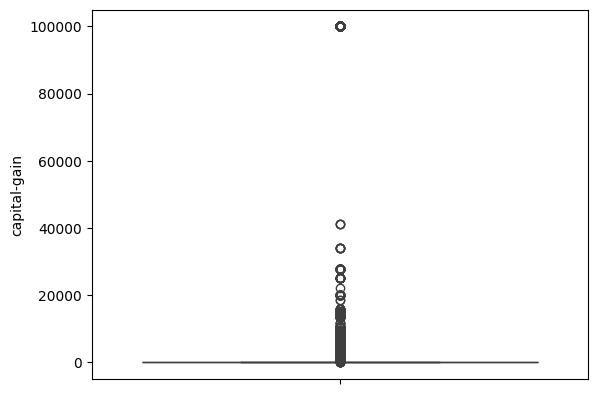

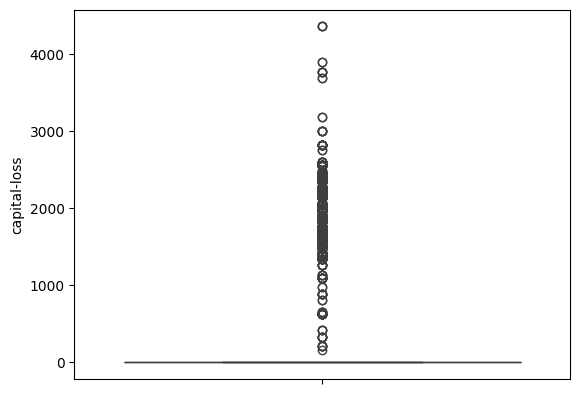

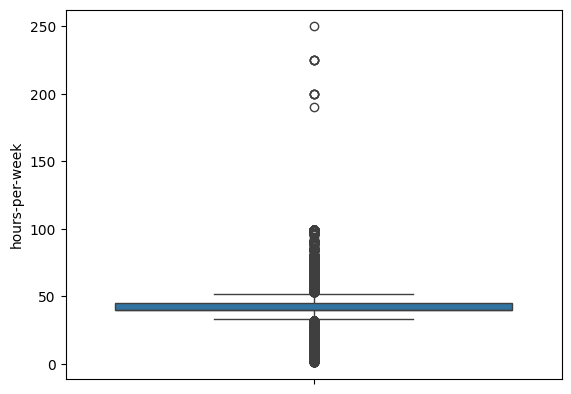

In [ ]:
sns.boxplot(df['age'])
plt.show()
sns.boxplot(df['fnlwgt'])
plt.show()
sns.boxplot(df['education-num'])
plt.show()
sns.boxplot(df['capital-gain'])
plt.show()
sns.boxplot(df['capital-loss'])
plt.show()
sns.boxplot(df['hours-per-week'])
plt.show()

In [ ]:
q1 = df['age'].quantile(0.25)
q2 = df['age'].quantile(0.50)
q3 = df['age'].quantile(0.75)

print(f'Q1 = {q1}\nQ2 = {q2}\nQ3 = {q3}')

iqr = q3 - q1

up_lim = q3 + (1.5 * iqr)
low_lim = q1 - (1.5 * iqr)

print(f'IQR = {iqr}\nUp_lim = {up_lim}\nLow_lim = {low_lim}')

Q1 = 28.0
Q2 = 37.0
Q3 = 47.0
IQR = 19.0
Up_lim = 75.5
Low_lim = -0.5


In [ ]:
df.loc[df['age'] > up_lim,'age'] = up_lim

df.loc[df['age'] < low_lim,'age'] = low_lim

In [ ]:
df.loc[df['fnlwgt'] > 100000,'fnlwgt'] = 100000

In [ ]:
df[df['education-num']<=4]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
15,34.0,Private,100000,7th-8th,4,Married-civ-spouse,Transport-moving,Husband,Amer-Indian-Eskimo,Male,0,0,45.0,Mexico,<=50K
56,46.0,Private,100000,5th-6th,3,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40.0,Mexico,<=50K
61,32.0,Private,100000,7th-8th,4,Married-spouse-absent,Prof-specialty,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
79,31.0,Local-gov,100000,7th-8th,4,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,40.0,United-States,<=50K
160,68.0,Private,38317,1st-4th,2,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,20.0,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48638,24.0,Private,100000,7th-8th,4,Married-civ-spouse,Farming-fishing,Own-child,White,Female,0,0,40.0,Mexico,<=50K.
48645,56.0,Private,100000,7th-8th,4,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,40.0,Dominican-Republic,<=50K.
48766,57.0,Private,100000,7th-8th,4,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,44.0,United-States,>50K.
48782,60.0,Private,100000,7th-8th,4,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,60.0,United-States,<=50K.


In [ ]:
q1 = df['education-num'].quantile(0.25)
q2 = df['education-num'].quantile(0.50)
q3 = df['education-num'].quantile(0.75)

print(f'Q1 = {q1}\nQ2 = {q2}\nQ3 = {q3}')

iqr = q3 - q1

up_lim = q3 + (1.5 * iqr)
low_lim = q1 - (1.5 * iqr)

print(f'IQR = {iqr}\nUp_lim = {up_lim}\nLow_lim = {low_lim}')

Q1 = 9.0
Q2 = 10.0
Q3 = 12.0
IQR = 3.0
Up_lim = 16.5
Low_lim = 4.5


In [ ]:
df.loc[df['education-num'] > up_lim,'education-num'] = up_lim

df.loc[df['education-num'] < low_lim,'education-num'] = low_lim

/tmp/ipykernel_485/1603447711.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '16.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[df['education-num'] > up_lim,'education-num'] = up_lim


In [ ]:
q1 = df['hours-per-week'].quantile(0.25)
q2 = df['hours-per-week'].quantile(0.50)
q3 = df['hours-per-week'].quantile(0.75)

iqr = q3 - q1

up_lim = q3 + (1.5 * iqr)
low_lim = q1 - (1.5 * iqr)

df.loc[df['hours-per-week'] > up_lim,'hours-per-week'] = up_lim

df.loc[df['hours-per-week'] < low_lim,'hours-per-week'] = low_lim

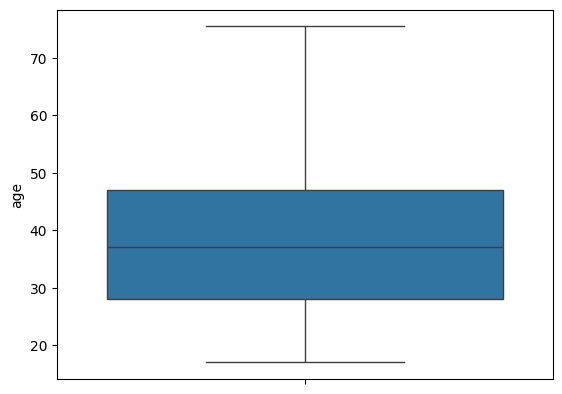

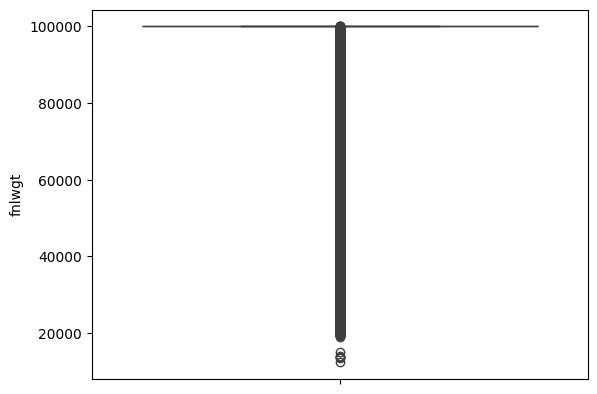

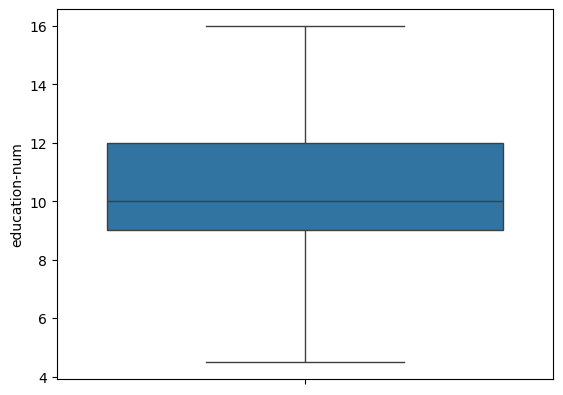

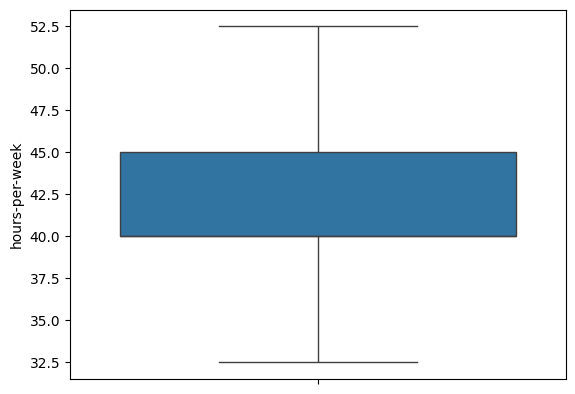

In [ ]:
sns.boxplot(df['age'])
plt.show()
sns.boxplot(df['fnlwgt'])
plt.show()
sns.boxplot(df['education-num'])
plt.show()
sns.boxplot(df['hours-per-week'])
plt.show()

# Encoding


In [ ]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,United-States,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,32.5,United-States,<=50K
2,38.0,Private,100000,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,100000,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,100000,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [ ]:
df['workclass'].unique()

array(['State-gov', 'Self-emp-not-inc', 'Private', 'Federal-gov',
       'Local-gov', 'Self-emp-inc', 'Without-pay', 'Never-worked'],
      dtype=object)

In [ ]:
df['education'].unique()

array(['Bachelors', 'HS-grad', '11th', 'Masters', '9th', 'Some-college',
       'Assoc-acdm', 'Assoc-voc', '7th-8th', 'Doctorate', 'Prof-school',
       '5th-6th', '10th', '1st-4th', 'Preschool', '12th'], dtype=object)

In [ ]:
df['marital-status'].unique()

array(['Never-married', 'Married-civ-spouse', 'Divorced',
       'Married-spouse-absent', 'Separated', 'Married-AF-spouse',
       'Widowed'], dtype=object)

In [ ]:
df['occupation'].unique()

array(['Adm-clerical', 'Exec-managerial', 'Handlers-cleaners',
       'Prof-specialty', 'Other-service', 'Sales', 'Craft-repair',
       'Transport-moving', 'Farming-fishing', 'Machine-op-inspct',
       'Tech-support', 'Protective-serv', 'Armed-Forces',
       'Priv-house-serv'], dtype=object)

In [ ]:
df['relationship'].unique()

array(['Not-in-family', 'Husband', 'Wife', 'Own-child', 'Unmarried',
       'Other-relative'], dtype=object)

In [ ]:
df['race'].unique()

array(['White', 'Black', 'Asian-Pac-Islander', 'Amer-Indian-Eskimo',
       'Other'], dtype=object)

In [ ]:
df['sex'].unique()

array(['Male', 'Female'], dtype=object)

In [ ]:
df['native-country'].unique()

array(['United-States', 'Cuba', 'Jamaica', 'India', 'Mexico', 'South',
       'Puerto-Rico', 'Honduras', 'England', 'Germany', 'Iran',
       'Philippines', 'Italy', 'Columbia', 'Cambodia', 'Thailand',
       'Canada', 'Ecuador', 'Laos', 'Taiwan', 'Haiti', 'Portugal',
       'Dominican-Republic', 'El-Salvador', 'Poland', 'France',
       'Guatemala', 'China', 'Japan', 'Yugoslavia', 'Peru',
       'Outlying-US(Guam-USVI-etc)', 'Scotland', 'Trinadad&Tobago',
       'Greece', 'Nicaragua', 'Vietnam', 'Hong', 'Ireland', 'Hungary',
       'Holand-Netherlands'], dtype=object)

In [ ]:
df['income'].unique()

array(['<=50K', '>50K', '<=50K.', '>50K.'], dtype=object)

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['income'] = le.fit_transform(df['income'])

In [ ]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,United-States,0
1,50.0,Self-emp-not-inc,83311,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,32.5,United-States,0
2,38.0,Private,100000,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,0
3,53.0,Private,100000,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,0
4,28.0,Private,100000,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,0


In [ ]:
df1=df.copy

In [ ]:
df = pd.get_dummies(df, dtype = int, drop_first= True)

In [ ]:
df.head()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39.0,77516,13.0,2174,0,40.0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50.0,83311,13.0,0,0,32.5,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,38.0,100000,9.0,0,0,40.0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
3,53.0,100000,7.0,0,0,40.0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,28.0,100000,13.0,0,0,40.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
x=df.drop('income', axis=1)

# K Means Clustering

In [ ]:
#  using elbow method to find the optimum number of clusters
from sklearn.cluster import KMeans

wcss = []
for i in range(3,9):
  kmeans =KMeans(n_clusters=i, init= 'k-means++', random_state=42)
  kmeans.fit(x)
  wcss.append(kmeans.inertia_)

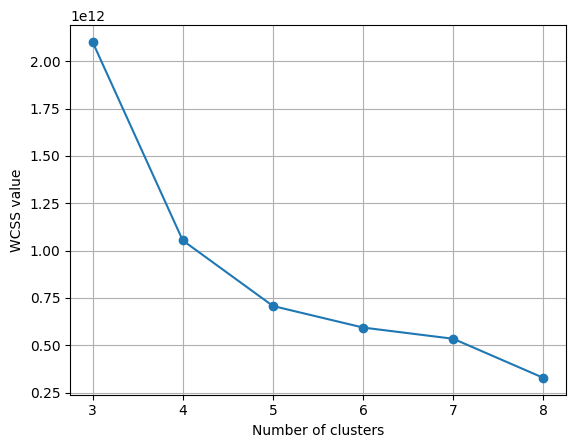

In [ ]:
plt.plot(range(3,9),wcss,'o-')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS value')
plt.grid()

In [ ]:
# elbow is appearing at k=4
# we can create kmeans model with no. of clusters=4

kmeans1 = KMeans(n_clusters=4, init='k-means++', random_state=42)
y_kmeans = kmeans1.fit_predict(x)

In [ ]:
print(y_kmeans)

[1 1 0 ... 0 0 0]


In [ ]:
#silhoutte score for kmean clustering

from sklearn.metrics import silhouette_score
sil_kmeans =  silhouette_score(x,y_kmeans)
print(sil_kmeans)

0.8875543582341633


# Agglomerative hierarchichal clustering

In [ ]:
x_sample = x.sample(n=10000, random_state=42).copy()

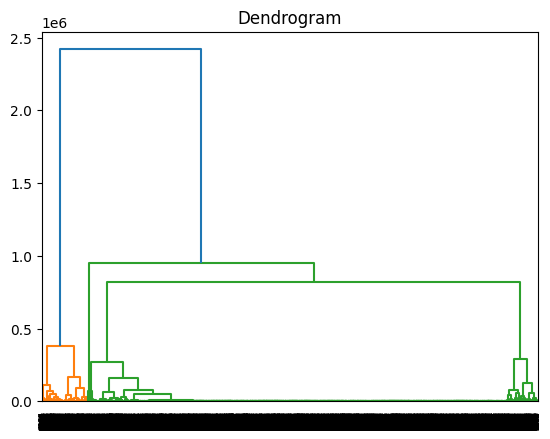

In [ ]:
# using dentrogram to find the optimum number of clusters
import scipy.cluster.hierarchy as sch

dentrogram = sch.dendrogram(sch.linkage(x_sample,method='ward'))
plt.title('Dendrogram')
plt.show()

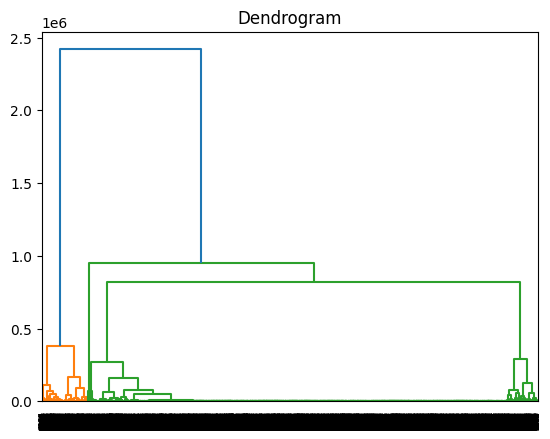

In [ ]:
# using dentrogram to find the optimum number of clusters
import scipy.cluster.hierarchy as sch

dentrogram = sch.dendrogram(sch.linkage(x_sample,method='ward'))
plt.title('Dendrogram')
plt.show()

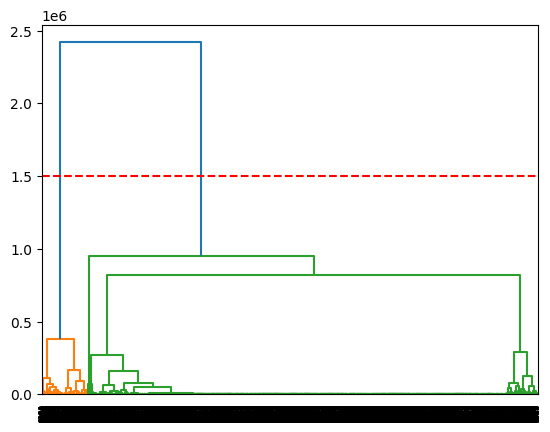

In [ ]:
dentrogram = sch.dendrogram(sch.linkage(x_sample,method='ward'))
plt.axhline(y=1500000,color='red',linestyle='--')

In [ ]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters=2, linkage = 'ward')
y_hc = hc.fit_predict(x_sample)

In [ ]:
silhoutte_avg =  silhouette_score(x_sample,y_hc)
print(silhoutte_avg )

0.8811429639744052
